# Exciter comparison: bladeRF vs RF generator

All algorithms come from the registries in `phase_pipeline.py` (`MPP_EXTRACTORS`, `PHASE_CALCS`, `COMBINERS`) and are
picked by name in the settings cell below, so a new algorithm registered there is usable here by name.

1. **Selected pairs**: for each `(A, B, run)` in `PAIRS`, both directions (A <- B, B <- A) in both datasets: the
   trace with the fitted channel windows, the unidirectional phases and the combined link phase
   `COMBINERS[COMBINE_ALGO]` (original: `((phi_AB + phi_BA) / 2) mod 180`).
2. **Top-N noisiest links**: per-link θ̂ SD over runs (as `phase_pipeline.py`), the `TOP_N` highest over both
   exciters, each shown as θ̂ per run plus the traces of its most deviating run.

In [23]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

HERE = Path(os.getcwd())  # notebook runs from phase_calc_improvements/
sys.path.insert(0, str(HERE))
import phase_pipeline as pp

# ---------------- algorithms (names from phase_pipeline's registries) ----------------
MPP_ALGO = "robust"         # pp.MPP_EXTRACTORS: per-channel voltage extraction
PHASE_ALGO = "pct70"        # pp.PHASE_CALCS:    unidirectional phase from the extraction
COMBINE_ALGO = "original"   # pp.COMBINERS:      link phase from the two directions
print("MPP:", list(pp.MPP_EXTRACTORS), "| phase:", list(pp.PHASE_CALCS), "| combine:", list(pp.COMBINERS))

# ---------------- data ----------------
DATA_DIR = HERE.parent / "multitag_organized_exciter_comparison_data"
DATASETS = ["bladerf", "rf_gen"]

# ---------------- section 1: selected pairs ----------------
RUN_IDX = 1          # default "Run Exp Num" (0..49) for pairs given without one
PAIRS = [            # (tagA, tagB, run); both directions are processed. run optional -> RUN_IDX.
    ("Tag8", "Tag16", 1),   # None -> N_RANDOM_PAIRS random pairs at RUN_IDX
    ("Tag8", "Tag16", 2),
    # ("Tag1", "Tag16", 1),
    # ("Tag1", "Tag17", 1),
    # ("Tag2", "Tag4", 1),
    # ("Tag3", "Tag7", 1),
]
N_RANDOM_PAIRS = 4
SEED = 2

# ---------------- section 2: top-N links by θ̂ SD ----------------
TOP_N = 10
TOP_SCOPE = "all"            # "all" = rank over both exciters together, or one dataset name, e.g. "rf_gen"
USE_PIPELINE_OUTPUT = True   # reuse out/<mpp>__<phase>__original/uni_phases.csv if phase_pipeline.py made it

SAVE_DIR = None      # set to a folder to also save each figure as PNG

FREQ_COL, RUN_COL, REP_COL = pp.FREQ_COL, pp.RUN_COL, pp.REP_COL
PHASE_COL = "Unidirectional Phase (deg)"

MPP: ['original', 'robust'] | phase: ['original', 'pct70', 'sections'] | combine: ['original']


In [24]:
# resolve algorithms + load raw traces (cached by phase_pipeline in ../.cache)
for kind, name, reg in [("MPP_ALGO", MPP_ALGO, pp.MPP_EXTRACTORS), ("PHASE_ALGO", PHASE_ALGO, pp.PHASE_CALCS),
                        ("COMBINE_ALGO", COMBINE_ALGO, pp.COMBINERS)]:
    if name not in reg:
        raise ValueError(f"{kind}={name!r} unknown, choose from {list(reg)}")
mpp_fn, phase_fn, combine_fn = pp.MPP_EXTRACTORS[MPP_ALGO], pp.PHASE_CALCS[PHASE_ALGO], pp.COMBINERS[COMBINE_ALGO]
ALGO_TAG = f"mpp={MPP_ALGO}, phase={PHASE_ALGO}, combine={COMBINE_ALGO}"

data = {name: pp.load_traces(DATA_DIR / name) for name in DATASETS}
channels = pp.channels_of(DATA_DIR / DATASETS[0])
hw_config = pp.pco.load_hw_config()
tag_mac_mapping = pp.pco.load_tag_mac_mapping()

for name, df in data.items():
    print(f"{name}: {len(df)} rows, {df.groupby(['Rx', 'Tx']).ngroups} links, "
          f"runs {df[RUN_COL].min()}..{df[RUN_COL].max()}, channels {channels}")
print("algorithms:", ALGO_TAG)

bladerf: 10500 rows, 210 links, runs 0..49, channels [1, 3, 4, 6, 7, 8]
rf_gen: 10500 rows, 210 links, runs 0..49, channels [1, 3, 4, 6, 7, 8]
algorithms: mpp=robust, phase=pct70, combine=original


In [25]:
# choose pairs: both directions must exist in both datasets
directed = set.intersection(*(set(map(tuple, df[["Rx", "Tx"]].drop_duplicates().values))
                              for df in data.values()))
common_pairs = sorted({tuple(sorted(l)) for l in directed if (l[1], l[0]) in directed})
if PAIRS is None:
    rng = np.random.default_rng(SEED)
    PAIRS = [common_pairs[i] for i in rng.choice(len(common_pairs), size=N_RANDOM_PAIRS, replace=False)]
PAIRS = [(p[0], p[1], p[2] if len(p) > 2 else RUN_IDX) for p in PAIRS]   # -> (A, B, run)
missing = [p for p in PAIRS if tuple(sorted(p[:2])) not in common_pairs]
if missing:
    raise ValueError(f"pairs without both directions in both datasets: {missing}")
print("pairs:", PAIRS)

pairs: [('Tag8', 'Tag16', 1), ('Tag8', 'Tag16', 2)]


In [26]:
# extraction + phase with the selected algorithms, and the trace plot
def get_row(df, rx, tx, run):
    rows = df[(df["Rx"] == rx) & (df["Tx"] == tx) & (df[RUN_COL] == run)]
    if rows.empty:
        raise KeyError(f"no row for {rx} <- {tx}, run {run}")
    return rows.iloc[0]


def process_row(row, mpp_algo=None, phase_algo=None):
    """Extraction (MPP_ALGO) + unidirectional phase (PHASE_ALGO) for one MPP row; overridable per call."""
    m_fn = pp.MPP_EXTRACTORS[mpp_algo or MPP_ALGO]
    p_fn = pp.PHASE_CALCS[phase_algo or PHASE_ALGO]
    v = np.asarray(row[pp.VOLT_COL], dtype=float)
    mpp = m_fn(v, pp.row_meta(row), channels)
    phase = p_fn(mpp, tag_mac_mapping[row["Rx"]], tag_mac_mapping[row["Tx"]], hw_config,
                 float(row[FREQ_COL]) * 1e6)
    rate = row.get("Sample Rate (Hz)")
    dt = 1.0 / rate if rate is not None and np.isfinite(rate) and rate > 0 else 1.0
    return dict(mpp=mpp, voltages=v, time=np.arange(len(v)) * dt, dt=dt, phase=phase,
                medians=mpp["medians"], spikes=mpp.get("spikes"))


def plot_extraction(ax, row, res, label):
    t, v, dt, mpp = res["time"], res["voltages"], res["dt"], res["mpp"]
    ax.plot(t, v, ".", markersize=2, color="#2a78d6", label="ADC samples")
    lo, hi = np.percentile(v, [0.5, 99.5])   # a single spike would flatten the trace
    margin = max((hi - lo) * 0.25, 0.05)
    ax.set_ylim(lo - margin, hi + margin)
    if "windows" in mpp:
        edges = sorted({b for w in mpp["windows"].values() for b in w})
        ax.axvspan(t[0], edges[0] * dt, color="#e1e0d9", alpha=0.6, label="outside fitted sweep")
        ax.axvspan(edges[-1] * dt, t[-1], color="#e1e0d9", alpha=0.6)
        for e in edges:
            ax.axvline(e * dt, color="#4a3aa8", linewidth=1.2)
        for ch, (a, b) in mpp["windows"].items():
            m = mpp["medians"][ch]
            ax.hlines(m, a * dt, b * dt, color="#e34948", linewidth=2, zorder=3)
            ax.annotate(f"ch{ch}", ((a + b) / 2 * dt, m), textcoords="offset points",
                        xytext=(0, 6), ha="center", fontsize=7, color="#52514e")
    sp = res["spikes"]
    if sp is not None and np.any(sp):   # samples the extractor replaced (usually off-scale): top edge
        ax.plot(t[sp], np.full(int(np.sum(sp)), hi + margin * 0.8), "v", color="#e34948",
                markersize=6, label=f"replaced ({int(np.sum(sp))})", zorder=4)
    ax.set_title(f"[{label}] {row['Rx']} <- {row['Tx']} | {row[FREQ_COL]:g} MHz | run {row[RUN_COL]} | "
                 f"rep {row[REP_COL]} | phase {res['phase']:.2f} deg", fontsize=9)
    ax.set_xlabel("Time [s]" if dt != 1.0 else "Sample")
    ax.set_ylabel("ADC out [mV]")
    ax.grid(color="#e1e0d9", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.legend(fontsize=7, frameon=False, loc="upper left")


def combined_deg(phase_ab, phase_ba):
    return float(np.rad2deg(combine_fn(np.array([phase_ab]), np.array([phase_ba]))[0]))


def save(fig, name):
    if SAVE_DIR:
        os.makedirs(SAVE_DIR, exist_ok=True)
        fig.savefig(os.path.join(SAVE_DIR, name), dpi=150)

## 1. Selected pairs


Tag8 <-> Tag16 | run 1
  bladerf   Tag8 <- Tag16 phase     1.35 deg (stored     1.10) | ch1=555.77, ch3=566.76, ch4=556.57, ch6=497.22, ch7=561.42, ch8=523.12
  bladerf  Tag16 <- Tag8  phase   163.82 deg (stored   163.75) | ch1=428.63, ch3=414.28, ch4=404.59, ch6=494.32, ch7=411.00, ch8=472.95
  bladerf  combined = 82.58 deg
  rf_gen    Tag8 <- Tag16 phase    -5.57 deg (stored    -5.41) | ch1=202.64, ch3=209.43, ch4=206.23, ch6=175.71, ch7=208.21, ch8=186.01
  rf_gen   Tag16 <- Tag8  phase   170.14 deg (stored   170.02) | ch1=196.23, ch3=187.84, ch4=188.45, ch6=226.06, ch7=187.69, ch8=213.32
  rf_gen   combined = 82.29 deg


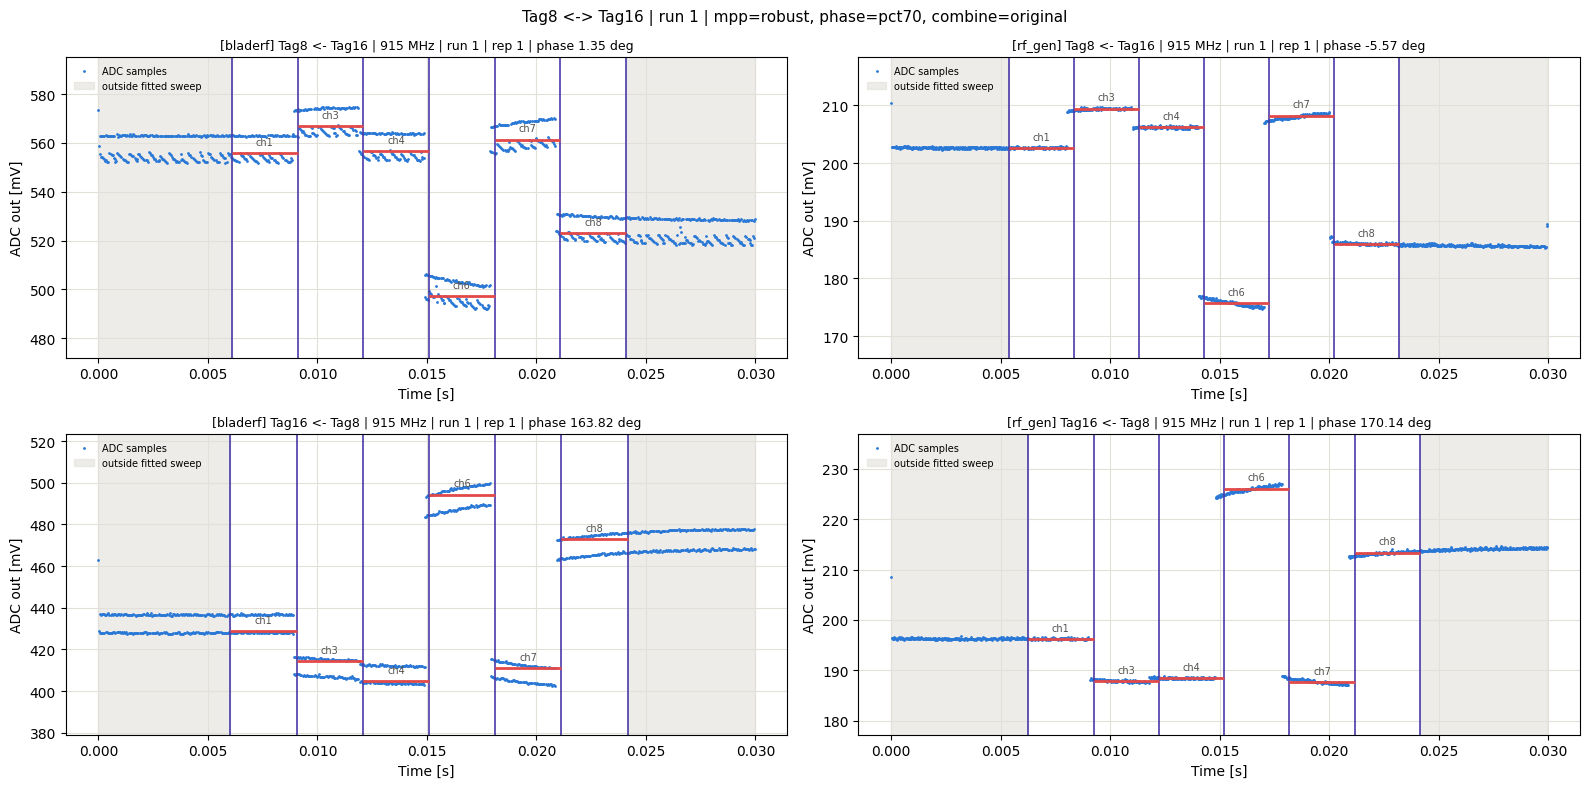


Tag8 <-> Tag16 | run 2
  bladerf   Tag8 <- Tag16 phase     0.72 deg (stored     0.45) | ch1=551.80, ch3=563.36, ch4=553.64, ch6=492.94, ch7=558.10, ch8=519.38
  bladerf  Tag16 <- Tag8  phase   164.44 deg (stored   164.27) | ch1=436.41, ch3=415.27, ch4=412.41, ch6=496.64, ch7=412.26, ch8=473.18
  bladerf  combined = 82.58 deg
  rf_gen    Tag8 <- Tag16 phase    -4.98 deg (stored    -4.87) | ch1=202.79, ch3=209.51, ch4=206.30, ch6=175.56, ch7=208.13, ch8=186.54
  rf_gen   Tag16 <- Tag8  phase   170.25 deg (stored    -3.37) | ch1=196.31, ch3=187.99, ch4=188.56, ch6=226.21, ch7=187.76, ch8=213.28
  rf_gen   combined = 82.63 deg


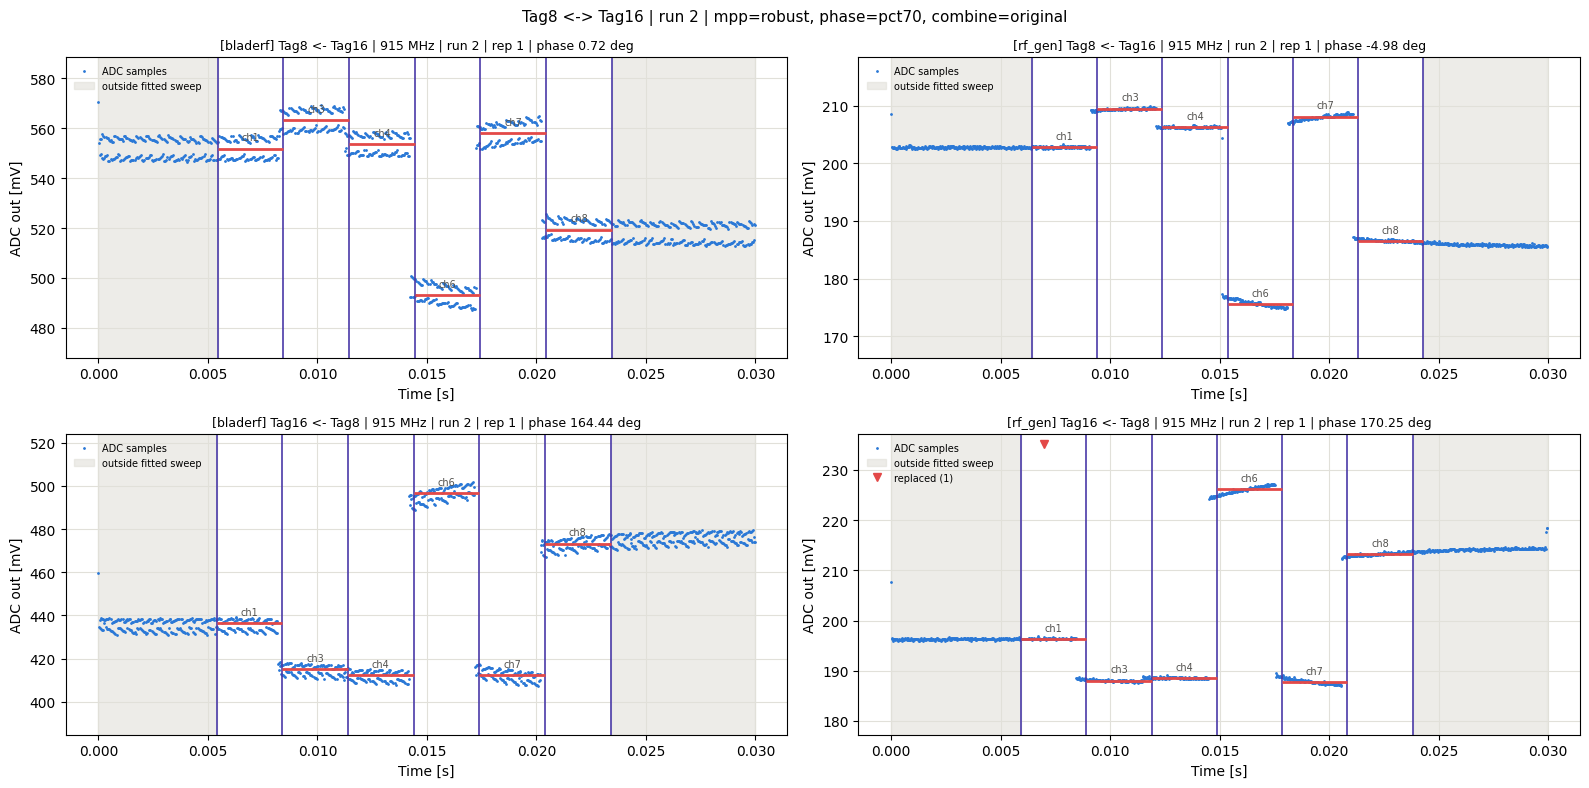


combined link phase (deg):
 dataset         bladerf  rf_gen  diff (bladerf - rf_gen)
pair       run                                          
Tag8-Tag16 1      82.58   82.29                     0.29
           2      82.58   82.63                    -0.05


In [27]:
# rows = direction (A <- B, B <- A), columns = dataset
results = []
for a, b, run in PAIRS:
    directions = [(a, b), (b, a)]   # (Rx, Tx)
    fig, axes = plt.subplots(len(directions), len(DATASETS),
                             figsize=(8 * len(DATASETS), 4 * len(directions)), squeeze=False)
    print(f"\n{a} <-> {b} | run {run}")
    for j, name in enumerate(DATASETS):
        uni = []
        for i, (rx, tx) in enumerate(directions):
            row = get_row(data[name], rx, tx, run)
            res = process_row(row)
            plot_extraction(axes[i, j], row, res, name)
            uni.append(res["phase"])
            med = ", ".join(f"ch{c}={m:.2f}" for c, m in res["medians"].items())
            print(f"  {name:8s} {rx:>5s} <- {tx:<5s} phase {res['phase']:8.2f} deg "
                  f"(stored {row[PHASE_COL]:8.2f}) | {med}")
        comb = combined_deg(*uni)
        print(f"  {name:8s} combined = {comb:.2f} deg")
        results.append(dict(pair=f"{a}-{b}", dataset=name, run=run,
                            phase_ab=uni[0], phase_ba=uni[1], combined_deg=comb))
    fig.suptitle(f"{a} <-> {b} | run {run} | {ALGO_TAG}", fontsize=11)
    fig.tight_layout()
    save(fig, f"{a}_{b}_run{run}.png")
    plt.show()

results = pd.DataFrame(results)
summary = results.pivot_table(index=["pair", "run"], columns="dataset", values="combined_deg", sort=False)
if set(DATASETS) == {"bladerf", "rf_gen"}:   # combined phase lives on a 180-degree circle
    summary["diff (bladerf - rf_gen)"] = ((summary["bladerf"] - summary["rf_gen"] + 90) % 180) - 90
print("\ncombined link phase (deg):\n", summary.round(2))

## 2. Top-N links by θ̂ standard deviation over runs

In [28]:
# unidirectional phases of every MPP with the selected algorithms (reused from phase_pipeline.py output if present)
pipe_csv = pp.OUT_ROOT / f"{MPP_ALGO}__{PHASE_ALGO}__original" / "uni_phases.csv"
if USE_PIPELINE_OUTPUT and pipe_csv.exists():
    print(f"using {pipe_csv.relative_to(HERE)}")
    uni_all = pd.read_csv(pipe_csv)
else:
    print("computing all unidirectional phases (run `python phase_pipeline.py --mpp ... --phase ...` to cache) …")
    parts = []
    for name, df in data.items():
        ph = pp.unidirectional_phases(df, mpp_fn, phase_fn, channels, hw_config, tag_mac_mapping)
        parts.append(df.drop(columns=[pp.VOLT_COL]).assign(phase_deg=ph, exciter=name))
    uni_all = pd.concat(parts, ignore_index=True)

bidir, sds = {}, []
for name in DATASETS:
    bidir[name] = pp.bidirectional(uni_all[uni_all["exciter"] == name], combine_fn)
    sds.append(pp.link_theta_sd(bidir[name], pp.load_positions(DATA_DIR / name), name))
link_sd = pd.concat(sds, ignore_index=True)

pool = link_sd if TOP_SCOPE == "all" else link_sd[link_sd["exciter"] == TOP_SCOPE]
top = pool.sort_values("theta_sd_deg", ascending=False).head(TOP_N).reset_index(drop=True)
print(f"median θ̂ SD: " + ", ".join(f"{k} {g['theta_sd_deg'].median():.2f}°" for k, g in link_sd.groupby("exciter")))
print(f"top {TOP_N} links by θ̂ SD ({TOP_SCOPE}; {ALGO_TAG}):")
print(top[["exciter", "T1", "T2", "dist_cm", "n_runs", "theta_sd_deg"]].round(2).to_string())

using out/robust__pct70__original/uni_phases.csv
  bladerf: no positions.txt, using the rf_gen exp-1 layout
  rf_gen: no positions.txt, using the rf_gen exp-1 layout
median θ̂ SD: bladerf 1.01°, rf_gen 3.65°
top 10 links by θ̂ SD (all; mpp=robust, phase=pct70, combine=original):
   exciter  T1  T2  dist_cm  n_runs  theta_sd_deg
0   rf_gen   5  16   165.86      50         24.22
1  bladerf   2   9   102.86      50         22.78
2   rf_gen  15  18   138.00      50         18.16
3   rf_gen   5   6   189.66      50         17.89
4   rf_gen   2   4    92.00      50         17.51
5  bladerf   1  10   189.66      50         17.23
6   rf_gen   2   7    46.00      50         15.57
7   rf_gen   9  15   145.46      50         15.55
8  bladerf   7  19   145.46      50         15.30
9  bladerf   2  10   145.46      50         14.90


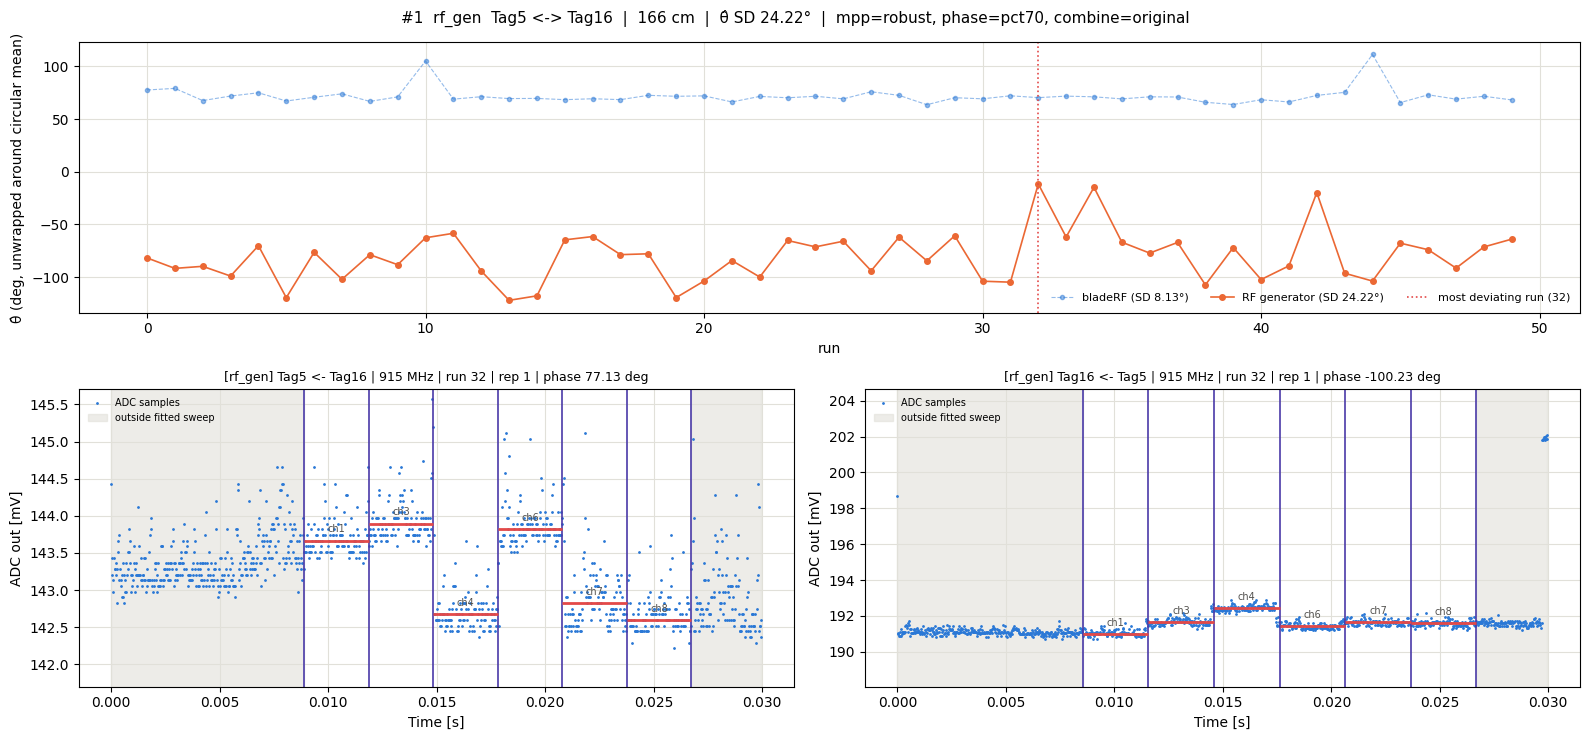

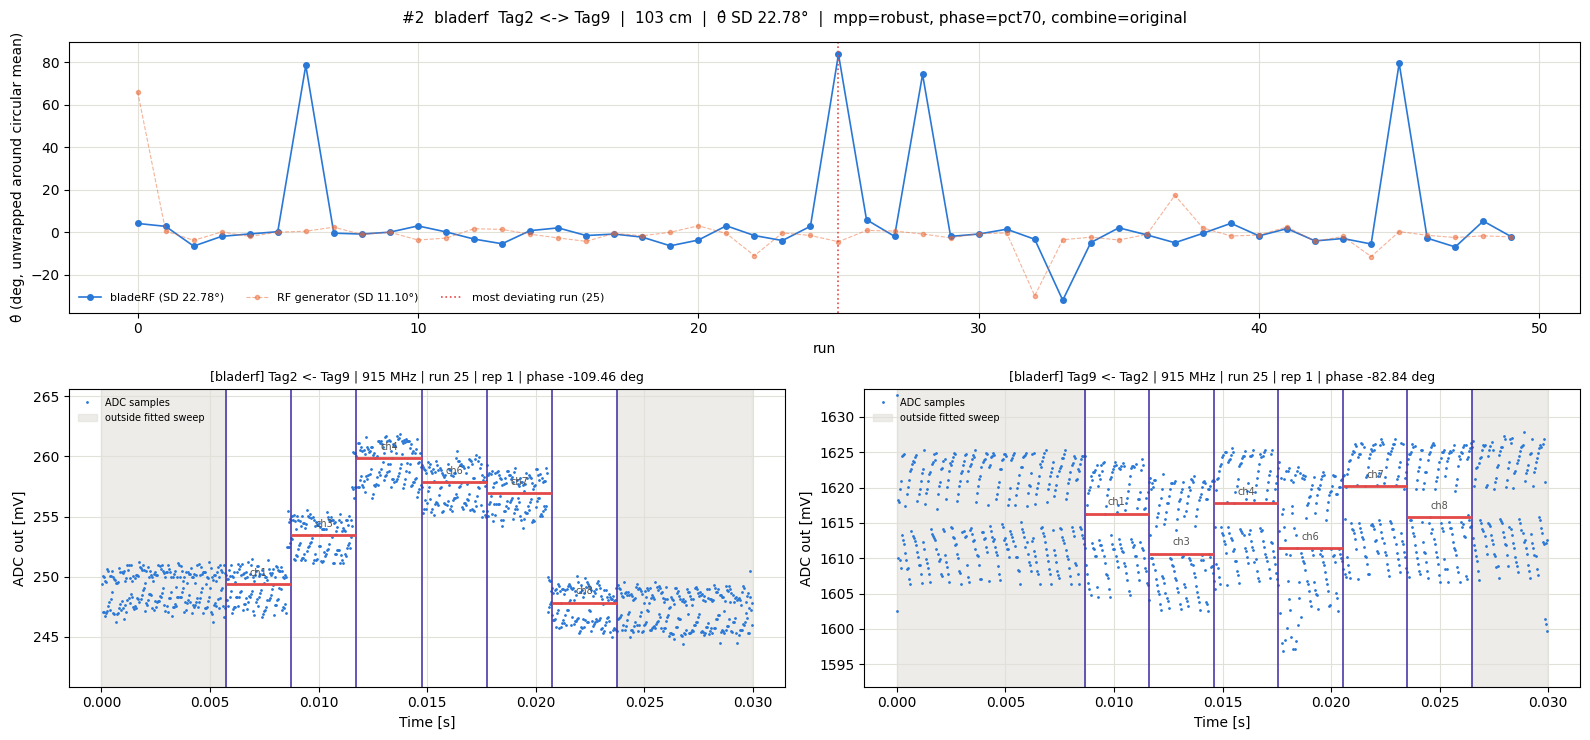

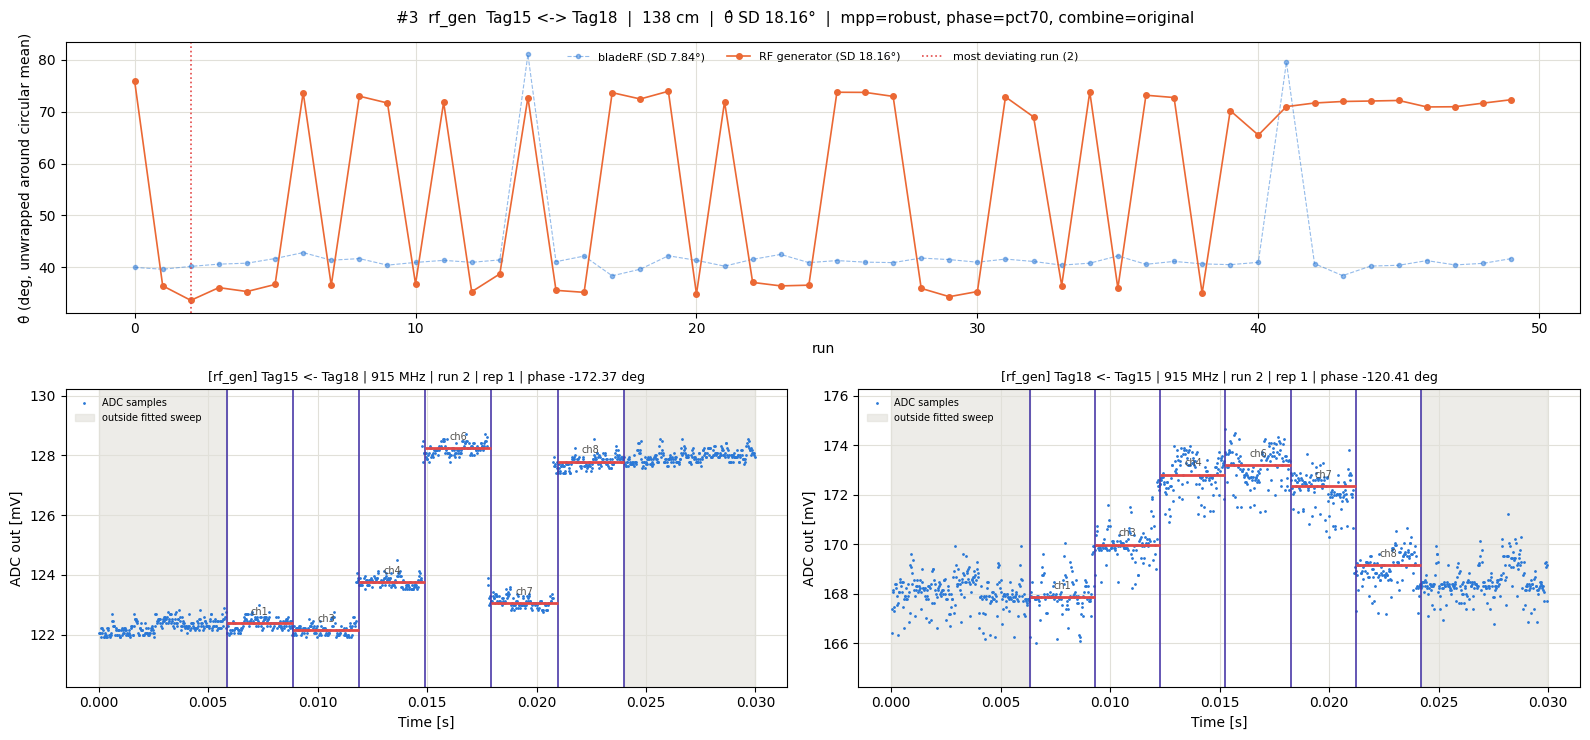

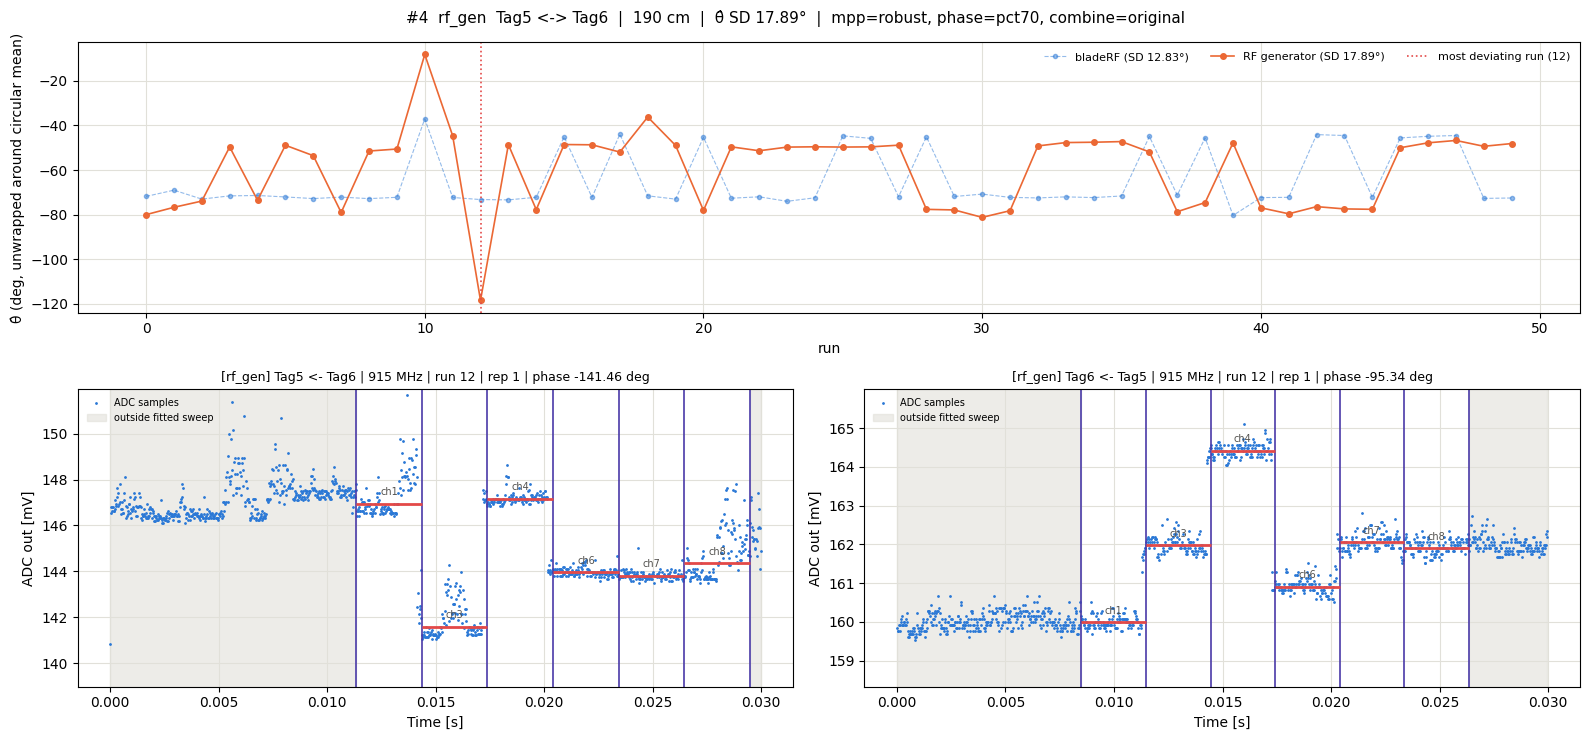

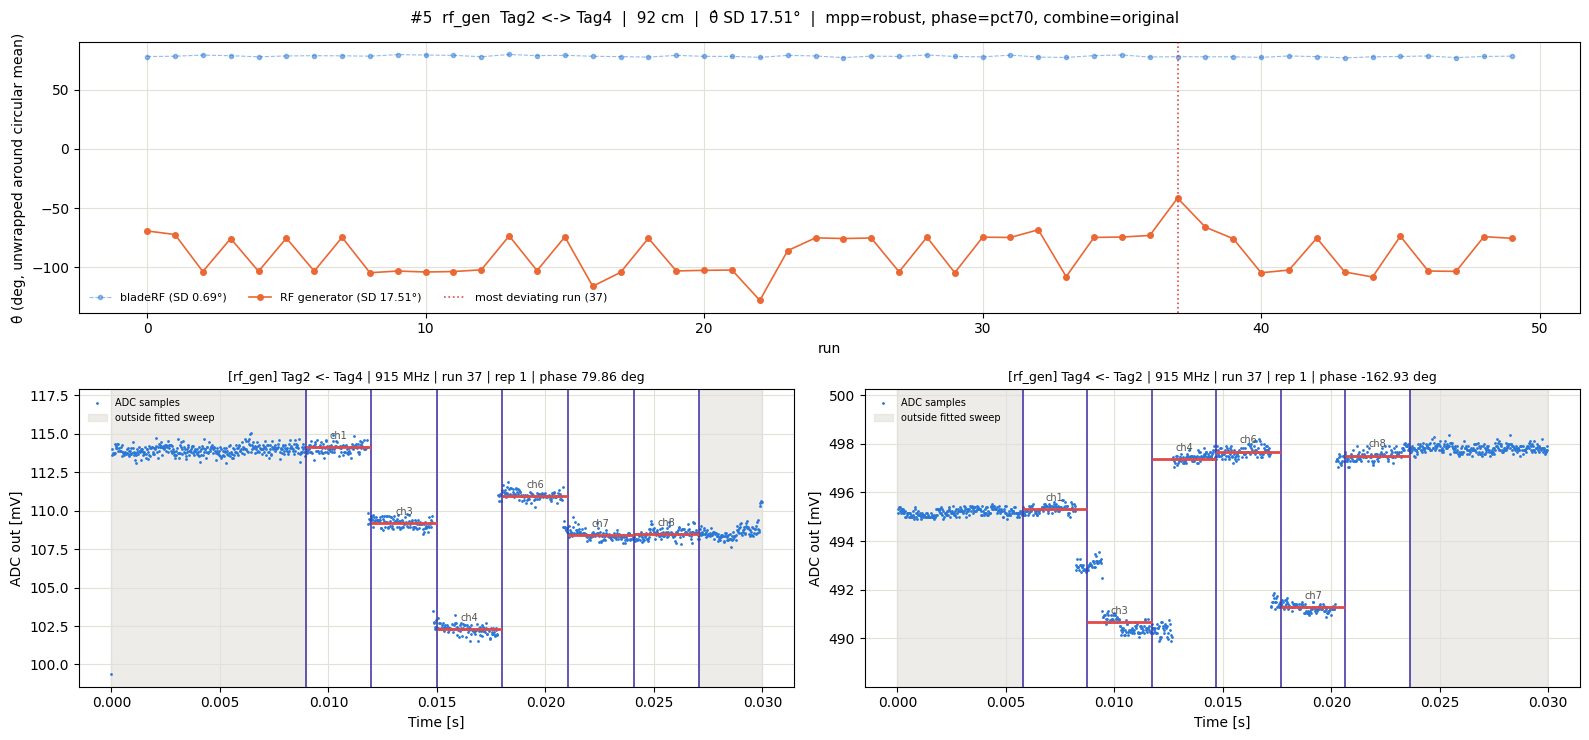

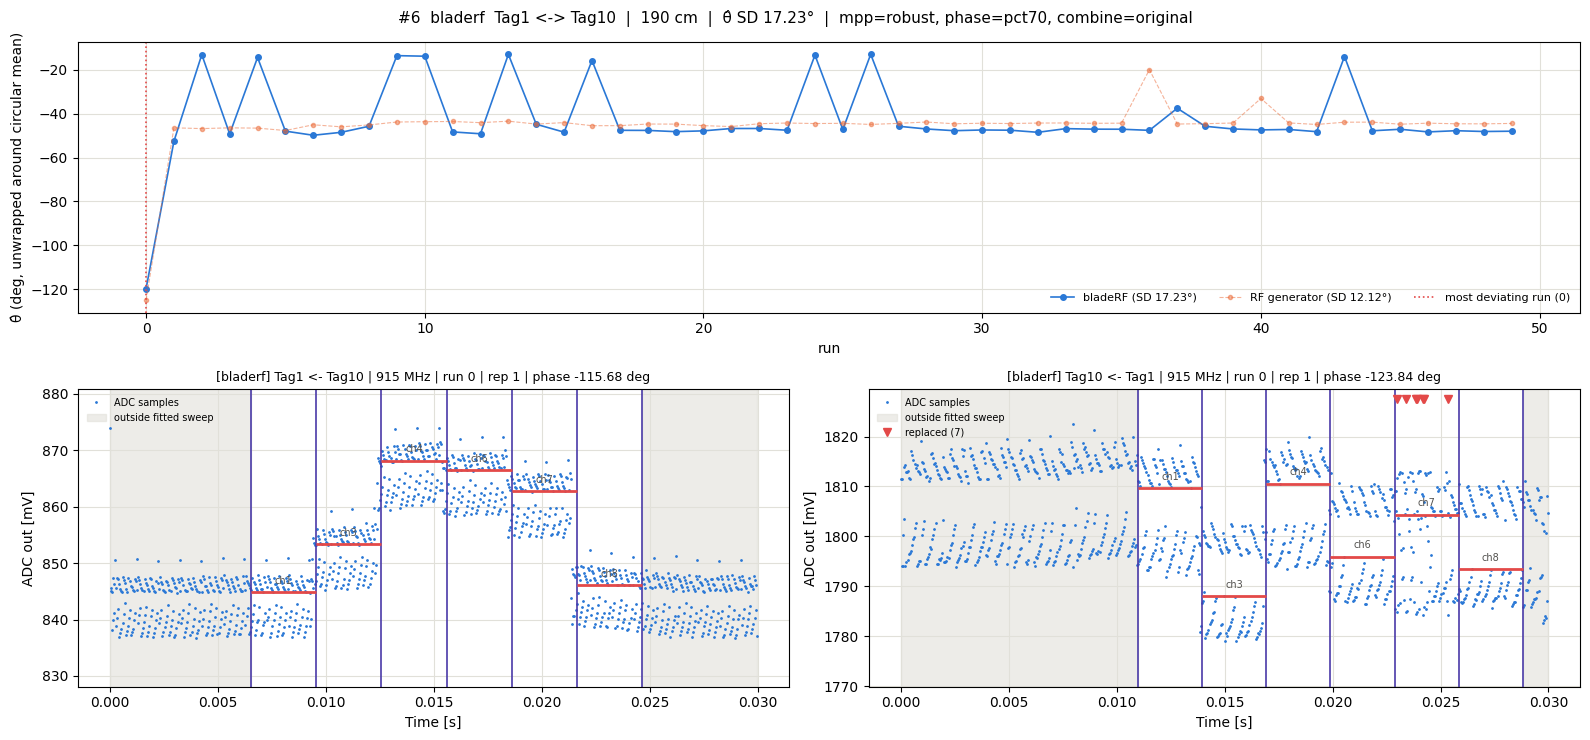

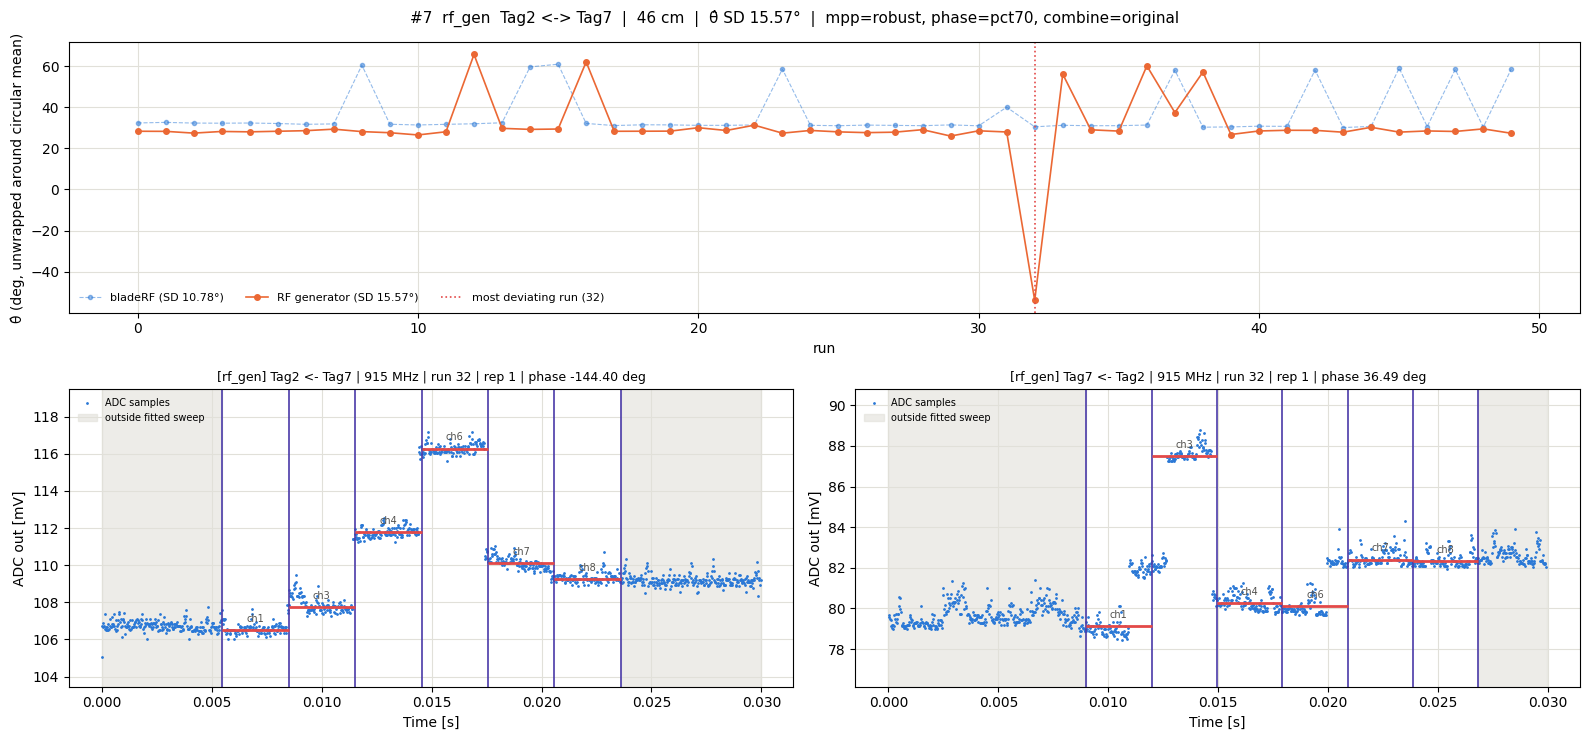

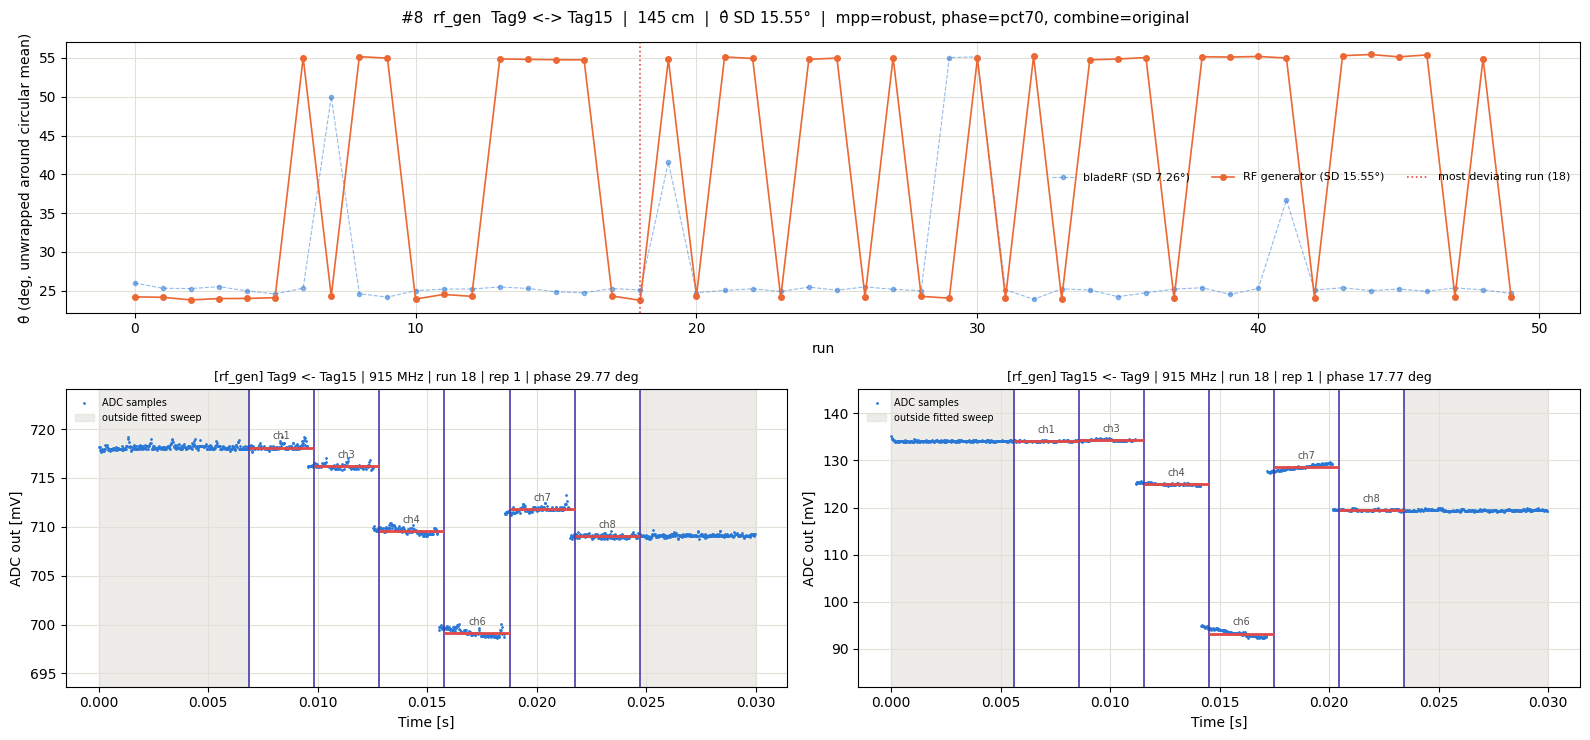

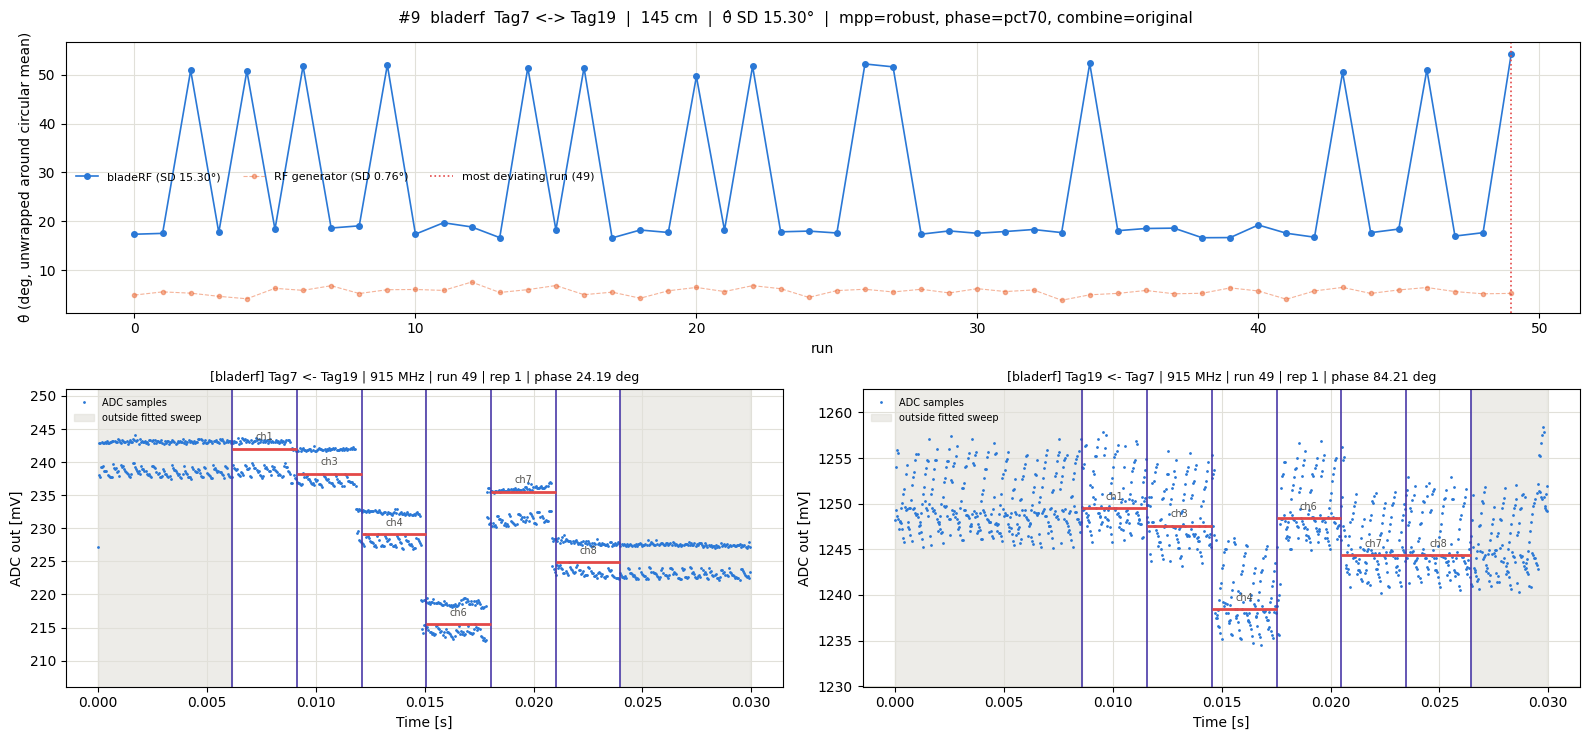

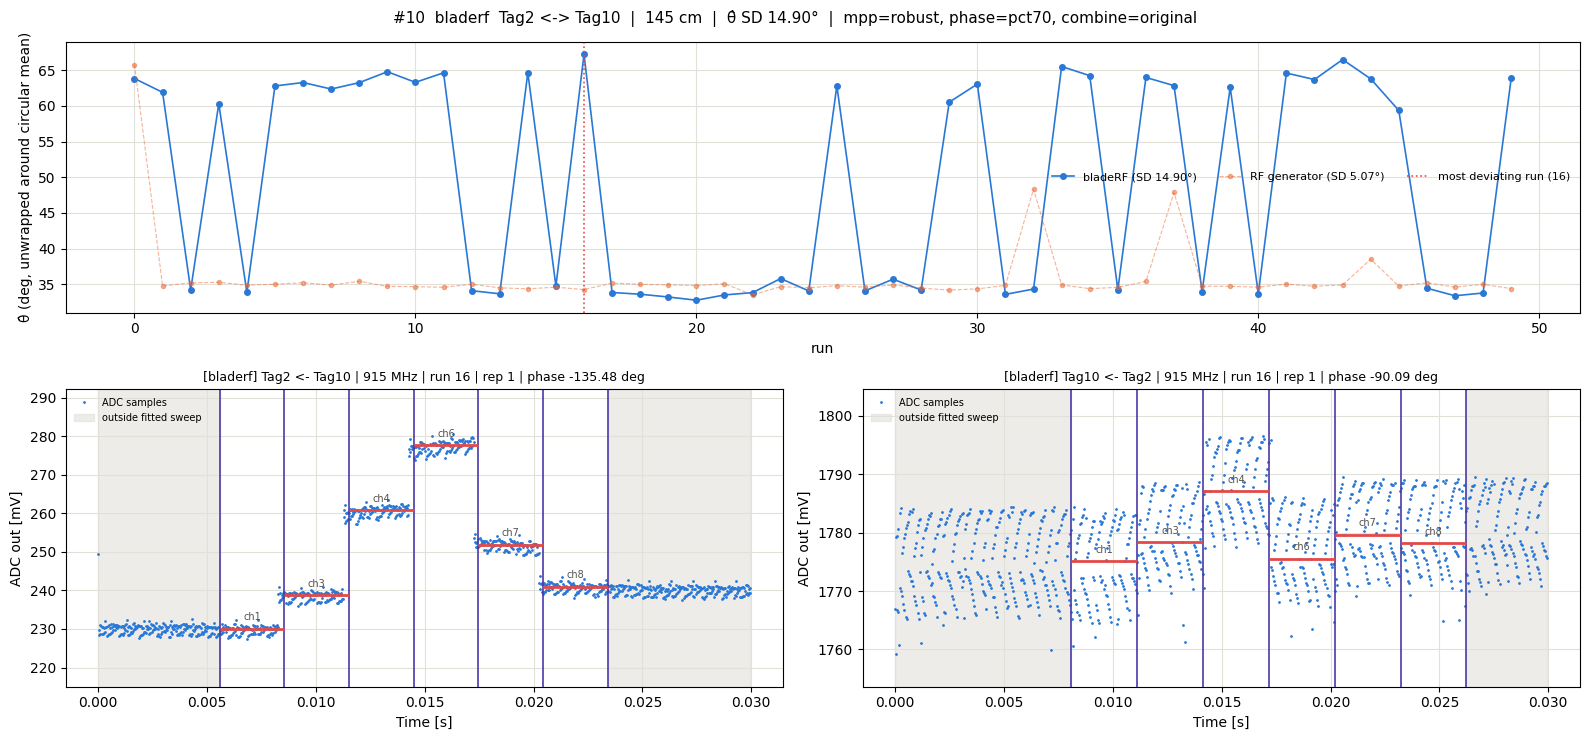

In [29]:
# per top link: θ̂ per run (both exciters, this one highlighted) + traces of its most deviating run
def runs_of(name, t1, t2):
    g = bidir[name][(bidir[name]["T1"] == t1) & (bidir[name]["T2"] == t2)].sort_values("run")
    th = g["THETA"].to_numpy(float)
    ref = np.angle(np.mean(np.exp(2j * th))) / 2                      # circular mean on the mod-π circle
    dev = (th - ref + np.pi / 2) % np.pi - np.pi / 2                  # signed deviation from it
    return g["run"].to_numpy(), np.rad2deg(ref + dev), np.rad2deg(dev)

colors = dict(zip(pp.EXCITERS, pp.COLORS))
for k, lk in top.iterrows():
    name, t1, t2 = lk["exciter"], int(lk["T1"]), int(lk["T2"])
    a, b = f"Tag{t1}", f"Tag{t2}"
    runs, theta, dev = runs_of(name, t1, t2)
    worst = int(runs[np.argmax(np.abs(dev))])

    fig = plt.figure(figsize=(16, 7.5))
    gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.1])
    ax0 = fig.add_subplot(gs[0, :])
    for other in DATASETS:
        r, th, _ = runs_of(other, t1, t2)
        ax0.plot(r, th, "o-" if other == name else "o--", markersize=4 if other == name else 3,
                 linewidth=1.2 if other == name else 0.8, alpha=1 if other == name else 0.5,
                 color=colors.get(other), label=f"{pp.EXCITERS.get(other, other)}"
                 f" (SD {link_sd.query('exciter == @other and T1 == @t1 and T2 == @t2')['theta_sd_deg'].iloc[0]:.2f}°)")
    ax0.axvline(worst, color="#e34948", linestyle=":", linewidth=1.2, label=f"most deviating run ({worst})")
    ax0.set_xlabel("run")
    ax0.set_ylabel("θ̂ (deg, unwrapped around circular mean)")
    ax0.grid(color="#e1e0d9", linewidth=0.8)
    ax0.legend(fontsize=8, frameon=False, ncol=3)
    for j, (rx, tx) in enumerate([(a, b), (b, a)]):
        ax = fig.add_subplot(gs[1, j])
        row = get_row(data[name], rx, tx, worst)
        plot_extraction(ax, row, process_row(row), name)
    fig.suptitle(f"#{k + 1}  {name}  {a} <-> {b}  |  {lk['dist_cm']:.0f} cm  |  θ̂ SD {lk['theta_sd_deg']:.2f}°  |  "
                 f"{ALGO_TAG}", fontsize=11)
    fig.tight_layout()
    save(fig, f"top{k + 1:02d}_{name}_{a}_{b}.png")
    plt.show()